# Catheter Artifact Detection Pipeline

**Complete end-to-end pipeline for detecting catheter shunt artifacts in brain MRI**

## Pipeline Steps:
1. **Setup & Imports** - Load dependencies
2. **Data Loading** - Load MRI and ground truth mask
3. **Preprocessing** - Registration and normalization
4. **Anchor Detection** - Find initial artifact in axial plane
5. **Multi-Planar Tracking** - Track in axial, coronal, sagittal
6. **3D Smoothing** - Clean and refine the result
7. **Inverse Registration** - Transform back to original space
8. **Evaluation** - Compute Dice score with ground truth
9. **Visualization** - Interactive 3D visualization

---

## 1. Setup & Imports

In [ ]:
# Install required packages
%pip install antspyx -q
%pip install plotly -q
%pip install scikit-image -q

In [10]:
# Core imports
import os
import numpy as np
from pathlib import Path

import ants

import SimpleITK as sitk

from skimage import filters, morphology, measure
from skimage.draw import polygon
from skimage.measure import regionprops

from scipy import ndimage
from scipy.spatial import ConvexHull
from scipy.ndimage import (
    center_of_mass, label as nd_label, binary_dilation, label,
    binary_erosion, binary_fill_holes, distance_transform_edt, generate_binary_structure, binary_closing, binary_opening
)

from collections import deque

# Visualization
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import matplotlib.pyplot as plt
from ipywidgets import interact, IntSlider, Dropdown

from preprocess import Preprocess
from artifact_segmentation.artifact_tracker import Tracker

import warnings
warnings.filterwarnings('ignore')

print("✓ All imports successful")

✓ All imports successful


## 2. Configuration & Paths

In [2]:
# Configuration
subject_number = '010'  # Change this for different subjects

# Paths
base_dir = Path('data/Train')  
image_path = base_dir / f'subj{subject_number}' / f'subj{subject_number}_image.nii.gz'
mask_path = base_dir / f'subj{subject_number}' / f'subj{subject_number}_artifact.nii.gz'

# Output directory
output_dir = Path('./outputs') / f'subject_{subject_number}'
output_dir.mkdir(parents=True, exist_ok=True)

print(f"Subject: {subject_number}")
print(f"Image: {image_path}")
print(f"Mask: {mask_path}")
print(f"Output: {output_dir}")

Subject: 010
Image: data/Train/subj010/subj010_image.nii.gz
Mask: data/Train/subj010/subj010_artifact.nii.gz
Output: outputs/subject_010


## 3. Data Loading

In [3]:
def load_data(image_path, mask_path):
    """
    Load MRI image and ground truth mask.
    
    Returns:
        img: ANTs image
        mask: ANTs mask
        img_array: Numpy array
        mask_array: Numpy array
    """
    print("Loading data...")
    
    # Load with ANTs
    img = ants.image_read(str(image_path))
    mask = ants.image_read(str(mask_path))
    
    # Get numpy arrays
    img_array = img.numpy()
    mask_array = mask.numpy().astype(bool)
    
    print(f"  Image shape: {img_array.shape}")
    print(f"  Mask sum: {mask_array.sum()} voxels")
    print(f"  Image range: [{img_array.min():.1f}, {img_array.max():.1f}]")
    
    return img, mask, img_array, mask_array

# Load data
original_img, original_mask, img_array, mask_array = load_data(image_path, mask_path)

Loading data...
  Image shape: (192, 224, 192)
  Mask sum: 14425 voxels
  Image range: [0.0, 505.7]


## 4. Preprocessing - Registration to Template

In [4]:
# Run preprocessing
preprocess = Preprocess()
reg_image, reg_mask, template = preprocess.preprocess_subject(str(image_path), str(mask_path), Path(base_dir / f'subj{subject_number}'))

print(f"\n✓ Preprocessing complete")
print(f"  Registered image shape: {reg_image.numpy().shape}")
print(f"  Registered mask sum: {reg_mask.numpy().sum()} voxels")


✓ Preprocessing complete
  Registered image shape: (193, 229, 193)
  Registered mask sum: 6104.0 voxels


## 6. Anchor Detection in Axial Plane

In [ ]:
def remove_noise(img_slice):
    thresh = filters.threshold_otsu(img_slice)
    rough_mask = img_slice > thresh

    cleaned = morphology.binary_closing(rough_mask, morphology.disk(3))
    labels = measure.label(cleaned)
    if labels.max() > 0:
        brain_blob = (labels == (np.argmax(np.bincount(labels.flat)[1:]) + 1))
    else:
        brain_blob = cleaned

    final_brain_mask = ndimage.binary_fill_holes(brain_blob)
    final_brain_mask = morphology.binary_closing(final_brain_mask, morphology.disk(8))
    
    return np.where(img_slice, final_brain_mask, 0)

def is_brain_like(contour, min_area=1000):
    y, x = contour[:, 0], contour[:, 1]
    area = 0.5 * np.abs(np.dot(x, np.roll(y, 1)) - np.dot(y, np.roll(x, 1)))
    
    if area < min_area:
        return False

    try:
        hull = ConvexHull(contour)
        solidity = area / hull.volume
    except:
        return "Invalid"

    if solidity > 0.98:
        return True
    else:
        return False

def get_brain_contour(img_slice):
    binary_mask = remove_noise(img_slice)
    
    if binary_mask.sum() < 100:
        return None

    contours = measure.find_contours(binary_mask.astype(float), 0.5)
    
    if len(contours) == 0:
        return None

    largest_contour = max(contours, key=len)
   
    brain_mask = np.zeros_like(img_slice, dtype=bool)
    rr, cc = polygon(largest_contour[:, 0], largest_contour[:, 1], img_slice.shape)
    brain_mask[rr, cc] = True
    
    return brain_mask, largest_contour

def estimate_artifact_region(img_slice, brain_mask):
    from skimage import morphology, measure
    import numpy as np

    # 1. Get the "Dents" (Air spaces inside the Hull but outside the Brain)
    hull = morphology.convex_hull_image(brain_mask)
    dents_mask = hull & ~brain_mask
    
    # 2. Cleanup: Remove tiny noise/pixels
    dents_mask = morphology.remove_small_objects(dents_mask, min_size=20)
    
    # 3. Label each space and check criteria
    labeled_dents = measure.label(dents_mask)
    regions = measure.regionprops(labeled_dents)
    
    best_mask = np.zeros_like(img_slice, dtype=bool)
    max_score = 0
    
    # Get the Hull boundary (perimeter) to check for overlap
    # Erosion trick: pixels on the edge of the hull
    hull_boundary = hull ^ morphology.binary_erosion(hull, morphology.disk(1))

    for reg in regions:
        # A. Check for Hull Boundary Overlap
        # If the dent touches the outer hull, it's a "boundary artifact"
        touches_boundary = np.logical_and(reg.image, hull_boundary[reg.slice]).any()
        
        if touches_boundary:
            # B. Check for Compactness (Roundness)
            # circularity = 4pi * Area / Perimeter^2
            perimeter = reg.perimeter
            area = reg.area
            circularity = (4 * np.pi * area) / (perimeter**2) if perimeter > 0 else 0
            
            # C. Score by Size + Circularity
            # We want compact (high circularity) and medium sized
            score = area * circularity
            
            if score > max_score:
                max_score = score
                best_mask = (labeled_dents == reg.label)

    return max_score, best_mask

def find_anchor_by_boundary_artifact_detection(img_data, target_slices, axis=2, verbose=True):
    candidate_slices = []
    
    for z in target_slices:
        img_slice = np.take(img_data, z, axis=axis)
        
        if img_slice.size == 0 or img_slice.max() == img_slice.min():
            continue
        
        result = get_brain_contour(img_slice)
        if result is None:
            continue

        brain_mask, contour = result
        
        if not is_brain_like(contour):
            continue
        
        # Detect artifacts (simple - no predefined search zone)
        artifact_score, artifact_mask = estimate_artifact_region(
            img_slice, 
            brain_mask
        )
        
        if artifact_mask.sum() > 0:
            n_clusters = label(artifact_mask)[1]
        else:
            n_clusters = 0
        
        # Store candidate
        if artifact_score > 0:
            candidate_slices.append({
                'slice_index': z,
                'artifact_score': artifact_score,
                'artifact_mask': artifact_mask,
                'brain_mask': brain_mask,
                'contour': contour,
                'n_clusters': n_clusters
            })
            
            if verbose:
                print(f"{z:<8} {n_clusters:<10} {'Yes':<15} {artifact_score:<15.3f}")
        else:
            if verbose and z % 20 == 0:
                print(f"{z:<8} {0:<10} {'No':<15} {0.0:<15.3f}")
    
    if len(candidate_slices) == 0:
        raise ValueError("No suitable anchor slice found!")
    
    # Find slice with strongest artifact
    best_candidate = max(candidate_slices, key=lambda x: x['artifact_score'])
    
    if verbose:
        print("\n" + "=" * 60)
        print(f"✓ ANCHOR SLICE: {best_candidate['slice_index']}")
        print("=" * 60)
        print(f"Artifact score:     {best_candidate['artifact_score']:.3f}")
        print(f"Number of clusters: {best_candidate['n_clusters']}")
        print(f"Total candidates:   {len(candidate_slices)}")
    
    return best_candidate['slice_index'], best_candidate

def refine_anchor_mask(mask, sigma=1.0):
    """
    Refines and smoothens the binary anchor mask.
    """
    if mask is None or mask.sum() == 0:
        return mask

    # 1. Fill any tiny internal pinholes
    refined = ndimage.binary_fill_holes(mask)

    # 2. Morphological Opening
    # This removes tiny 'hairs' or thin protrusions (spikes) 
    # without changing the overall size much.
    refined = morphology.binary_opening(refined, morphology.disk(2))

    # 3. Morphological Closing
    # This smoothens the outer boundary and bridges small gaps.
    refined = morphology.binary_closing(refined, morphology.disk(2))

    # 4. Gaussian Smoothing (Anti-aliasing)
    # Turning the mask into a float, blurring, and re-thresholding 
    # creates much smoother 'sub-pixel' looking curves.
    smoothed_float = filters.gaussian(refined.astype(float), sigma=sigma)
    refined = smoothed_float > 0.5  # Re-threshold at 50%

    return refined

def visualize_anchor_detection(img_slice, brain_mask, artifact_mask, 
                                     slice_index, artifact_score):
    """
    Simple visualization of detected artifacts
    """
    import matplotlib.pyplot as plt
    from scipy.ndimage import distance_transform_edt, label
    from skimage.measure import regionprops
    
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    
    # Row 1
    axes[0, 0].imshow(img_slice, cmap='gray')
    axes[0, 0].set_title(f'Slice {slice_index}\nOriginal')
    axes[0, 0].axis('off')
    
    axes[0, 1].imshow(img_slice, cmap='gray')
    axes[0, 1].contour(brain_mask, colors='yellow', linewidths=2)
    axes[0, 1].set_title('Brain Boundary')
    axes[0, 1].axis('off')
    
    # Show distance from boundary
    distance_map = distance_transform_edt(brain_mask)
    axes[0, 2].imshow(distance_map, cmap='viridis')
    axes[0, 2].contour(brain_mask, colors='white', linewidths=1, alpha=0.5)
    axes[0, 2].set_title('Distance from Boundary\n(brighter = deeper)')
    axes[0, 2].axis('off')
    
    # Row 2
    # Show zero/near-zero regions
    max_int = img_slice.max()
    threshold = max_int * 0.02
    near_zero = img_slice < threshold
    
    axes[1, 0].imshow(img_slice, cmap='gray')
    axes[1, 0].imshow(near_zero, cmap='Reds', alpha=0.5)
    axes[1, 0].set_title(f'Near-Zero Regions\n(< {threshold:.1f})')
    axes[1, 0].axis('off')
    
    # Show detected artifact
    axes[1, 1].imshow(img_slice, cmap='gray')
    axes[1, 1].imshow(artifact_mask, cmap='hot', alpha=0.7)
    axes[1, 1].contour(artifact_mask, colors='red', linewidths=2)
    axes[1, 1].set_title(f'Detected Artifact\nScore: {artifact_score:.3f}')
    axes[1, 1].axis('off')
    
    # Properties text
    if artifact_mask.sum() > 0:
        labeled_artifacts = label(artifact_mask)[0]
        props = regionprops(labeled_artifacts)
        
        properties_text = "Detected Artifacts:\n" + "─" * 25 + "\n"
        
        for i, region in enumerate(props, 1):
            area = region.area
            perimeter = region.perimeter
            circ = (4 * np.pi * area) / (perimeter ** 2) if perimeter > 0 else 0
            
            # Distance from boundary
            dist = distance_map[region.coords[:, 0], region.coords[:, 1]].mean()
            
            properties_text += (
                f"\nCluster {i}:\n"
                f"  Size: {area} pixels\n"
                f"  Circularity: {circ:.3f}\n"
                f"  Distance from edge: {dist:.1f}px\n"
                f"  Mean intensity: {img_slice[artifact_mask].mean():.1f}\n"
            )
    else:
        properties_text = "No artifacts detected"
    
    axes[1, 2].text(0.1, 0.5, properties_text, 
                   fontsize=9, family='monospace',
                   verticalalignment='center')
    axes[1, 2].axis('off')
    
    plt.tight_layout()
    print(f"✓ Saved: anchor_simple_{slice_index}.png")

✓ Saved: anchor_simple_112.png


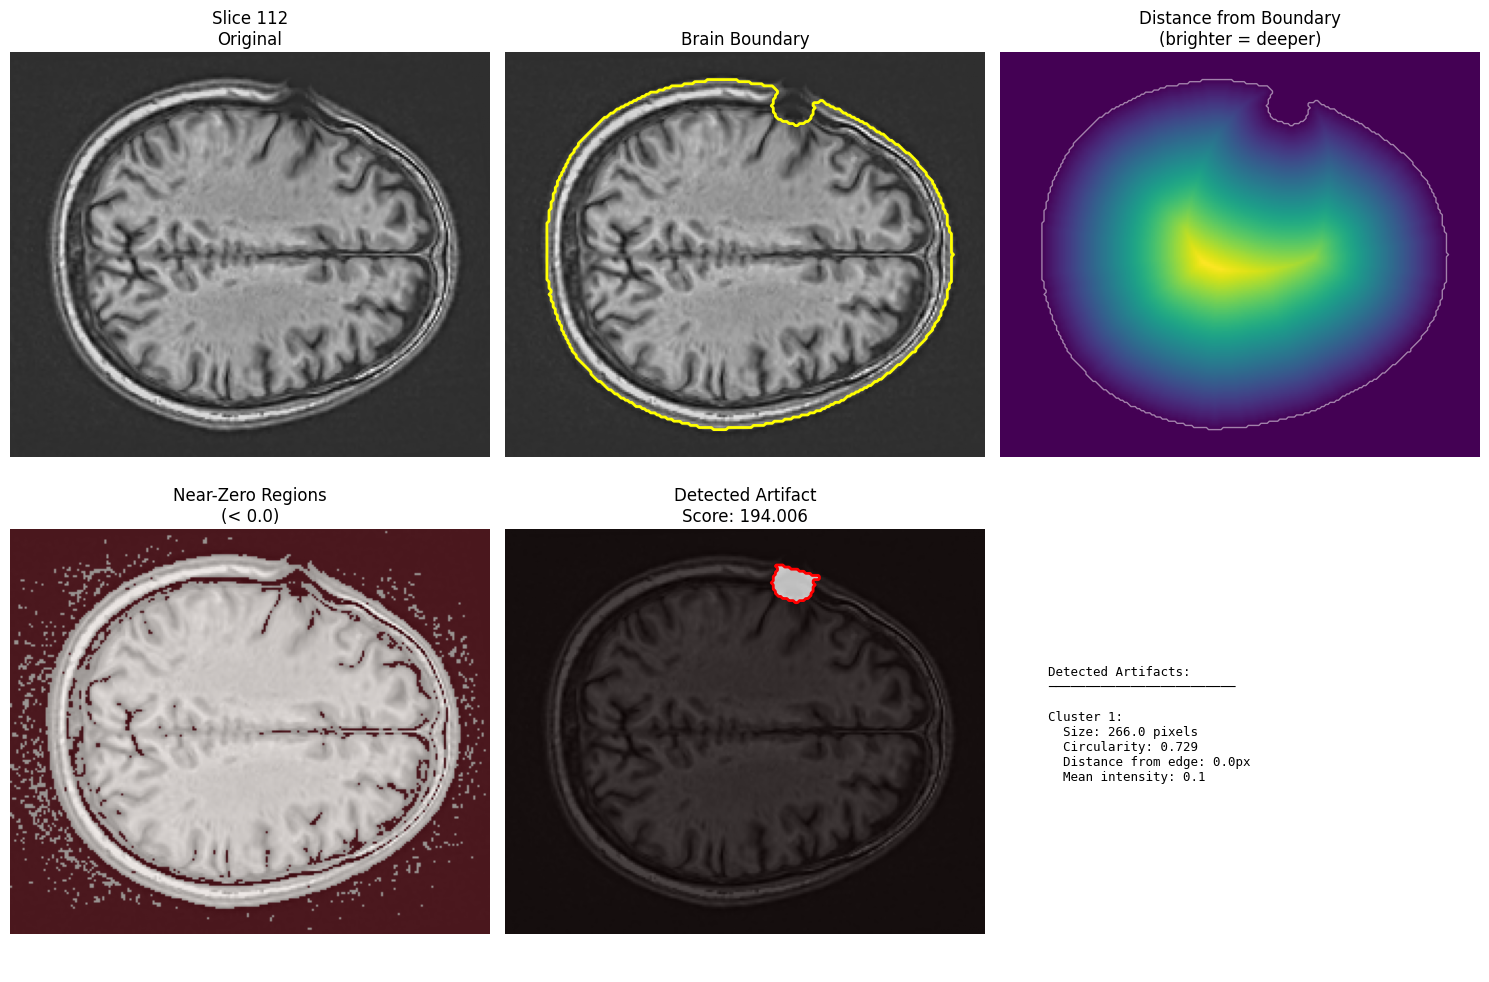

In [18]:
img_data = reg_image.numpy()
target_slices = range(0, 192)

# Find anchor
anchor_idx, anchor_data = find_anchor_by_boundary_artifact_detection(
    img_data,
    target_slices,
    axis=2,
    verbose=False
)

# Visualize anchor
visualize_anchor_detection(
    img_data[:, :, anchor_idx],
    anchor_data['brain_mask'],
    anchor_data['artifact_mask'],
    anchor_idx,
    anchor_data['artifact_score']
)

## 7. Multi-Planar Tracking

In [19]:
tracker = Tracker(search_radius=10)
artifact_combined, tracking_info = tracker.track_artifact(img_data, anchor_idx, anchor_data['artifact_mask'] )

MULTI-PLANAR CATHETER ARTIFACT TRACKING

STEP 1: AXIAL TRACKING (Axis=2, Z slices)
Axial anchor: Z slice = 112
Seed pixels: 266
Axial slices tracked: 102 → 113
Axial volume: 2198 voxels

CORONAL TRACKING (Axis=1, Y slices)
Coronal anchor: Y slice = 138
Seed pixels: 155
Coronal slices tracked: 131 → 145
Coronal volume: 2534 voxels

Axial + Coronal combined: 2955 voxels

SAGITTAL TRACKING (Axis=0, X slices)
Sagittal anchor: X slice = 25
Seed pixels: 294

STEP 4: FINAL COMBINATION
Final combined volume: 2955 voxels
Improvement over axial-only: 1.34x


## 8. 3D Smoothing

In [20]:
def compensate_volume_loss(original, smoothed, max_iterations=3):
    original_vol = original.sum()
    current_vol = smoothed.sum()
    
    if current_vol >= original_vol * 0.95:  # Within 5% is good enough
        return smoothed
        
    compensated = smoothed.copy()
    struct = generate_binary_structure(3, 1)
    
    for i in range(max_iterations):
        # Try dilating
        test = binary_dilation(compensated, structure=struct, iterations=1)
        test_vol = test.sum()
        
        # Stop if we overshoot
        if test_vol > original_vol * 1.05:
            break
        
        compensated = test
        print(f"    Iteration {i+1}: {test_vol} voxels ({test_vol/original_vol:.1%})")
        
        # Stop if close enough
        if test_vol >= original_vol * 0.95:
            break
    
    return compensated

def smooth_artifact(artifact_3d, preserve_volume=True):
    # Step 1: Remove small objects
    smoothed = morphology.remove_small_objects(artifact_3d, min_size=20)
    
    # Step 2: Fill holes in each 2D slice (faster than 3D)
    for z in range(smoothed.shape[2]):
        smoothed[:, :, z] = binary_fill_holes(smoothed[:, :, z])
    
    # Step 3: Morphological closing (fills gaps, smooths surfaces)
    struct = generate_binary_structure(3, 2)  # 18-connectivity (more aggressive)
    smoothed = binary_closing(smoothed, structure=struct, iterations=2)
    
    # Step 4: Morphological opening (removes thin protrusions)
    smoothed = binary_opening(smoothed, structure=struct, iterations=1)
    
    # Step 5: Remove remaining small holes
    smoothed = morphology.remove_small_holes(smoothed, area_threshold=50)

    if preserve_volume:
        smoothed = compensate_volume_loss(artifact_3d, smoothed)

    smoothed = tracker.keep_largest_component(smoothed)
    
    return smoothed

In [21]:
artifact_smoothed = smooth_artifact(artifact_combined)

## 9. Inverse Registration - Transform Back to Original Space

In [ ]:
def inverse_transform_mask(mask_array, original_img, reg_image, transforms):
    transforms = [
        path + '/reg_1InverseWarp.nii.gz',  # Already inverse
        path + '/reg_0GenericAffine.mat'     # Needs inversion
    ]
    mask_ants = ants.from_numpy(mask_array.astype('float32'))
    ants.copy_image_info(reg_image, mask_ants)
    
    # Apply transforms with correct inversion
    result = ants.apply_transforms(
        fixed=original_img,              # Target (original space)
        moving=mask_ants,                # Source (registered space)
        transformlist=transforms,
        whichtoinvert=[False, True],     # Don't invert InverseWarp, DO invert Affine
        interpolator='nearestNeighbor'
    )
    
    mask_original = result.numpy().astype(bool)
    print(f"  Output (original): {mask_original.sum()} voxels")
    
    return mask_original

path = str(base_dir / f'subj{subject_number}')
    
# Use INVERSE warp (already inverted) + Affine (needs inversion)



# USAGE:
predicted_mask_original = inverse_transform_mask(
    artifact_smoothed,
    original_img,
    reg_image,
    transforms
)

Transforming mask: registered → original space
  Input (registered): 3105 voxels
  Output (original): 3371 voxels


In [ ]:
start_interactive_viewer(reg_image, artifact_combined)

## 10. Evaluation - Dice Score

In [23]:
def compute_dice_score(pred, gt):
    """
    Compute Dice similarity coefficient.
    
    Dice = 2 * |A ∩ B| / (|A| + |B|)
    
    Args:
        pred: Predicted binary mask
        gt: Ground truth binary mask
        
    Returns:
        dice: Dice score (0-1)
        stats: Dictionary with detailed metrics
    """
    pred = pred.astype(bool)
    gt = gt.astype(bool)
    
    # Intersection and union
    intersection = np.logical_and(pred, gt).sum()
    pred_volume = pred.sum()
    gt_volume = gt.sum()
    
    # Dice score
    if pred_volume + gt_volume == 0:
        dice = 1.0  # Both empty
    else:
        dice = 2.0 * intersection / (pred_volume + gt_volume)
    
    # Additional metrics
    union = np.logical_or(pred, gt).sum()
    iou = intersection / union if union > 0 else 0.0
    
    # Sensitivity (recall) and Precision
    sensitivity = intersection / gt_volume if gt_volume > 0 else 0.0
    precision = intersection / pred_volume if pred_volume > 0 else 0.0
    
    # False positives and false negatives
    false_positive = np.logical_and(pred, ~gt).sum()
    false_negative = np.logical_and(~pred, gt).sum()
    
    stats = {
        'dice': dice,
        'iou': iou,
        'sensitivity': sensitivity,
        'precision': precision,
        'intersection': intersection,
        'pred_volume': pred_volume,
        'gt_volume': gt_volume,
        'false_positive': false_positive,
        'false_negative': false_negative
    }
    
    return dice, stats


# Compute metrics
dice_score, eval_stats = compute_dice_score(predicted_mask_original, mask_array)

print("="*80)
print("EVALUATION METRICS")
print("="*80)
print(f"\nDice Score:        {dice_score:.4f} ({dice_score*100:.2f}%)")
print(f"IoU:               {eval_stats['iou']:.4f}")
print(f"Sensitivity:       {eval_stats['sensitivity']:.4f}")
print(f"Precision:         {eval_stats['precision']:.4f}")
print(f"\nVolume Comparison:")
print(f"  Ground Truth:    {eval_stats['gt_volume']} voxels")
print(f"  Predicted:       {eval_stats['pred_volume']} voxels")
print(f"  Intersection:    {eval_stats['intersection']} voxels")
print(f"  False Positive:  {eval_stats['false_positive']} voxels")
print(f"  False Negative:  {eval_stats['false_negative']} voxels")
print("="*80)

EVALUATION METRICS

Dice Score:        0.3710 (37.10%)
IoU:               0.2277
Sensitivity:       0.2288
Precision:         0.9792

Volume Comparison:
  Ground Truth:    14425 voxels
  Predicted:       3371 voxels
  Intersection:    3301 voxels
  False Positive:  70 voxels
  False Negative:  11124 voxels


## 11. Comparison Visualization

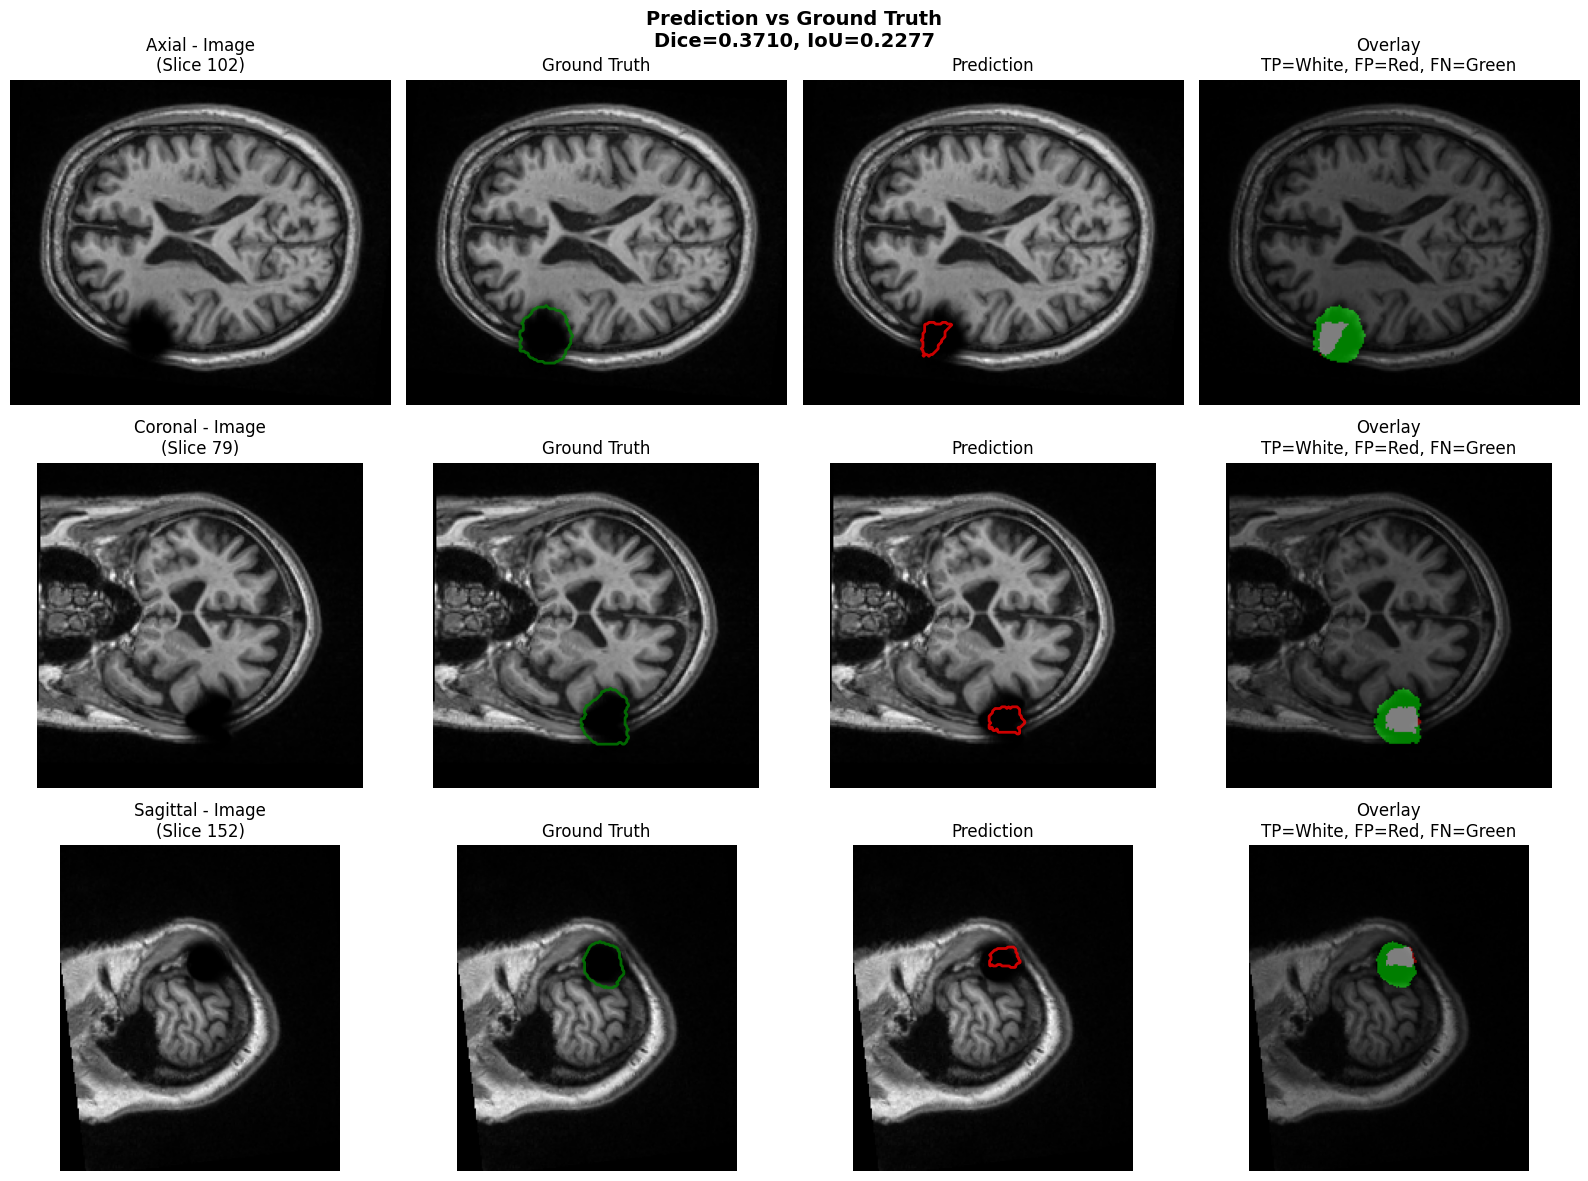

✓ Saved: outputs/subject_010/pred_vs_gt_comparison.png


In [24]:
def visualize_pred_vs_gt(img_data, pred_mask, gt_mask, slice_idx=None):
    """
    Visualize prediction vs ground truth in all three planes.
    """
    if slice_idx is None:
        # Use slice with most ground truth
        slice_idx = {
            'axial': int(gt_mask.sum(axis=(0, 1)).argmax()),
            'coronal': int(gt_mask.sum(axis=(0, 2)).argmax()),
            'sagittal': int(gt_mask.sum(axis=(1, 2)).argmax())
        }
    
    fig, axes = plt.subplots(3, 4, figsize=(16, 12))
    
    planes = [
        ('Axial', 2, slice_idx['axial']),
        ('Coronal', 1, slice_idx['coronal']),
        ('Sagittal', 0, slice_idx['sagittal'])
    ]
    
    for row, (plane_name, axis, idx) in enumerate(planes):
        # Extract slices
        img_slice = np.take(img_data, idx, axis=axis)
        pred_slice = np.take(pred_mask, idx, axis=axis)
        gt_slice = np.take(gt_mask, idx, axis=axis)
        
        # Column 1: Original image
        axes[row, 0].imshow(img_slice, cmap='gray')
        axes[row, 0].set_title(f'{plane_name} - Image\n(Slice {idx})')
        axes[row, 0].axis('off')
        
        # Column 2: Ground truth
        axes[row, 1].imshow(img_slice, cmap='gray')
        axes[row, 1].contour(gt_slice, colors='green', linewidths=2, alpha=0.8)
        axes[row, 1].set_title('Ground Truth')
        axes[row, 1].axis('off')
        
        # Column 3: Prediction
        axes[row, 2].imshow(img_slice, cmap='gray')
        axes[row, 2].contour(pred_slice, colors='red', linewidths=2, alpha=0.8)
        axes[row, 2].set_title('Prediction')
        axes[row, 2].axis('off')
        
        # Column 4: Overlay (TP=white, FP=red, FN=green)
        overlay = np.zeros((*img_slice.shape, 3))
        tp = pred_slice & gt_slice
        fp = pred_slice & ~gt_slice
        fn = ~pred_slice & gt_slice
        
        overlay[tp] = [1, 1, 1]  # True positive = white
        overlay[fp] = [1, 0, 0]  # False positive = red
        overlay[fn] = [0, 1, 0]  # False negative = green
        
        axes[row, 3].imshow(img_slice, cmap='gray')
        axes[row, 3].imshow(overlay, alpha=0.5)
        axes[row, 3].set_title('Overlay\nTP=White, FP=Red, FN=Green')
        axes[row, 3].axis('off')
    
    plt.suptitle(
        f'Prediction vs Ground Truth\nDice={dice_score:.4f}, IoU={eval_stats["iou"]:.4f}',
        fontsize=14, fontweight='bold'
    )
    plt.tight_layout()
    
    filename = output_dir / 'pred_vs_gt_comparison.png'
    plt.savefig(filename, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"✓ Saved: {filename}")


# Visualize
visualize_pred_vs_gt(img_array, predicted_mask_original, mask_array)

## 12. Interactive 3D Visualization

In [25]:
def visualize_3d_comparison(pred_mask, gt_mask, title="3D Comparison"):
    """
    Interactive 3D visualization comparing prediction and ground truth.
    """
    print("Generating 3D meshes...")
    
    # Generate meshes
    pad_pred = np.pad(pred_mask, 1, mode='constant')
    pad_gt = np.pad(gt_mask, 1, mode='constant')
    
    verts_pred, faces_pred, _, _ = measure.marching_cubes(pad_pred.astype(float), level=0.5)
    verts_gt, faces_gt, _, _ = measure.marching_cubes(pad_gt.astype(float), level=0.5)
    
    print(f"  Prediction: {len(verts_pred)} vertices")
    print(f"  Ground truth: {len(verts_gt)} vertices")
    
    # Create side-by-side subplots
    from plotly.subplots import make_subplots
    
    fig = make_subplots(
        rows=1, cols=3,
        specs=[[{'type': 'surface'}, {'type': 'surface'}, {'type': 'surface'}]],
        subplot_titles=('Ground Truth', 'Prediction', 'Overlay'),
        horizontal_spacing=0.05
    )
    
    # Ground truth (green)
    fig.add_trace(
        go.Mesh3d(
            x=verts_gt[:, 0], y=verts_gt[:, 1], z=verts_gt[:, 2],
            i=faces_gt[:, 0], j=faces_gt[:, 1], k=faces_gt[:, 2],
            color='green', opacity=0.5, name='GT', showscale=False
        ),
        row=1, col=1
    )
    
    # Prediction (red)
    fig.add_trace(
        go.Mesh3d(
            x=verts_pred[:, 0], y=verts_pred[:, 1], z=verts_pred[:, 2],
            i=faces_pred[:, 0], j=faces_pred[:, 1], k=faces_pred[:, 2],
            color='red', opacity=0.5, name='Pred', showscale=False
        ),
        row=1, col=2
    )
    
    # Overlay (both)
    fig.add_trace(
        go.Mesh3d(
            x=verts_gt[:, 0], y=verts_gt[:, 1], z=verts_gt[:, 2],
            i=faces_gt[:, 0], j=faces_gt[:, 1], k=faces_gt[:, 2],
            color='green', opacity=0.3, name='GT', showscale=False
        ),
        row=1, col=3
    )
    fig.add_trace(
        go.Mesh3d(
            x=verts_pred[:, 0], y=verts_pred[:, 1], z=verts_pred[:, 2],
            i=faces_pred[:, 0], j=faces_pred[:, 1], k=faces_pred[:, 2],
            color='red', opacity=0.3, name='Pred', showscale=False
        ),
        row=1, col=3
    )
    
    # Update layout
    fig.update_layout(
        title=f'{title}<br><sub>Dice={dice_score:.4f} | GT={gt_mask.sum()}px | Pred={pred_mask.sum()}px</sub>',
        width=1400,
        height=500,
        showlegend=False
    )
    
    # Match scenes
    fig.update_scenes(
        xaxis=dict(title='X', showgrid=False),
        yaxis=dict(title='Y', showgrid=False),
        zaxis=dict(title='Z', showgrid=False),
        aspectmode='data',
        camera=dict(eye=dict(x=1.5, y=1.5, z=1.5))
    )
    
    # Save
    filename = output_dir / '3d_comparison.html'
    fig.write_html(filename)
    print(f"✓ Saved: {filename}")
    print("  Open in browser for interactive 3D visualization!")
    
    fig.show()
    return fig


# Generate 3D comparison
fig_3d = visualize_3d_comparison(predicted_mask_original, mask_array)

Generating 3D meshes...
  Prediction: 2197 vertices
  Ground truth: 4853 vertices
✓ Saved: outputs/subject_010/3d_comparison.html
  Open in browser for interactive 3D visualization!
